In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import kagglehub
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification


In [ ]:
import os

DATA_DIR = None
for root, dirs, files in os.walk(path):  #os.walk(path) sary folders mein sy image wala folder find kary ga jis mein
    if "cardboard" in dirs and "glass" in dirs:
        DATA_DIR = root
        break

print("DATA_DIR:", DATA_DIR)
print(os.listdir(DATA_DIR))

DATA_DIR: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
['metal', 'glass', 'paper', 'trash', 'cardboard', 'plastic']


In [ ]:
IMG_SIZE = (224, 224) #har image ko 224x224 pixels ka bana denge, kyun ke MobileNetV2 isi size par train hua tha.
BATCH_SIZE = 32    #model ek baar mein 32 images dekh kar seekhta hai.
EPOCHS = 10

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE) #Seed random splitting ko fix karta hai taake training aur validation data overlap na karein aur results har baar same aayein.

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


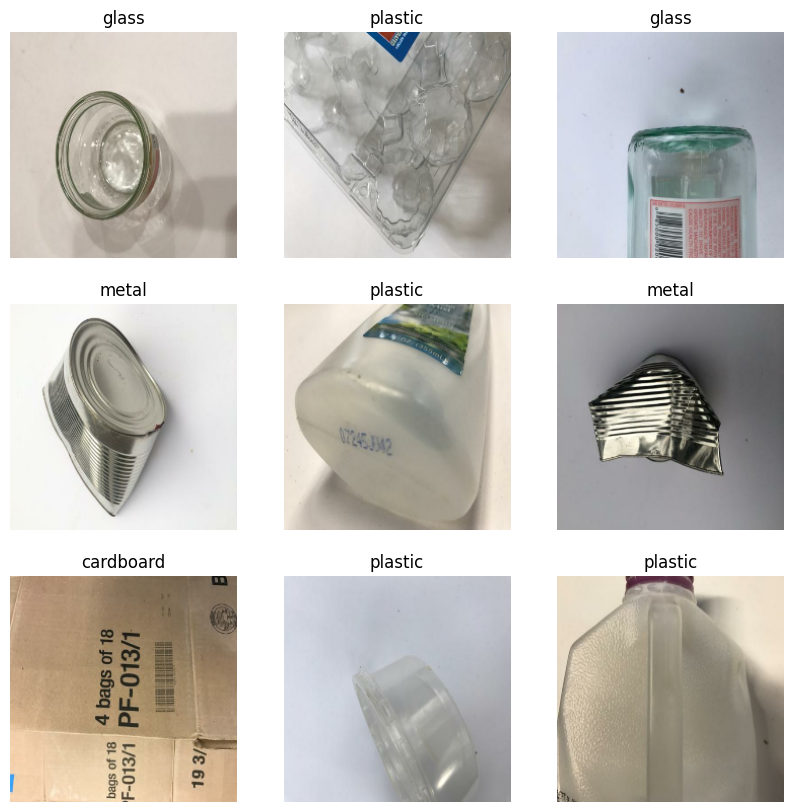

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False   # pehle se seekhi hui layers freeze

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),   # MobileNet ki zaroorat: pixels -1 se 1
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 ek pehle se trained model hai jo ImageNet ki 14 million images par seekha hua hai.
include_top=False: uski aakhri classification layer hata di (wo 1000 classes ke liye thi, hamein 6 chahiye).
weights="imagenet": seekhe hue weights load karo.
trainable = False: in layers ko freeze kar diya, yaani abhi inka seekha hua gyan change nahi hoga.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.5173 - loss: 1.2526 - val_accuracy: 0.7307 - val_loss: 0.7615
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.7072 - loss: 0.7575 - val_accuracy: 0.7743 - val_loss: 0.6485
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.7601 - loss: 0.6330 - val_accuracy: 0.8178 - val_loss: 0.5713
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.7824 - loss: 0.5800 - val_accuracy: 0.8356 - val_loss: 0.5334
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.7977 - loss: 0.5218 - val_accuracy: 0.8277 - val_loss: 0.5297
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.8200 - loss: 0.4883 - val_accuracy: 0.8297 - val_loss: 0.5202
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.8338 - loss: 0.4515 - val_accuracy: 0.8475 - val_loss: 0.4915
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.8378 - loss: 0.4408 - val_accuracy: 0.8099 - val_loss

In [ ]:
base_model.trainable = True    # yaha model ko finetune kiya hai kuch layer ko unfreez or kuch ko frozen karky taky model or accurate perform kary
for layer in base_model.layers[:-30]:   # sirf akhri 30 layers train hon
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),   # bohat chhota learning rate
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=8)

Epoch 1/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.7468 - loss: 0.7117 - val_accuracy: 0.8475 - val_loss: 0.5001
Epoch 2/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.7779 - loss: 0.5959 - val_accuracy: 0.8455 - val_loss: 0.5035
Epoch 3/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.7938 - loss: 0.5231 - val_accuracy: 0.8416 - val_loss: 0.5135
Epoch 4/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.8269 - loss: 0.4797 - val_accuracy: 0.8356 - val_loss: 0.5214
Epoch 5/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.8447 - loss: 0.4417 - val_accuracy: 0.8337 - val_loss: 0.5116
Epoch 6/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.8645 - loss: 0.3905 - val_accuracy: 0.8317 - val_loss: 0.5116
Epoch 7/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.8610 - loss: 0.3921 - val_accuracy: 0.8277 - val_loss: 0.5064
Epoch 8/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.8754 - loss: 0.3590 - val_accuracy: 0.8297 - val_loss:

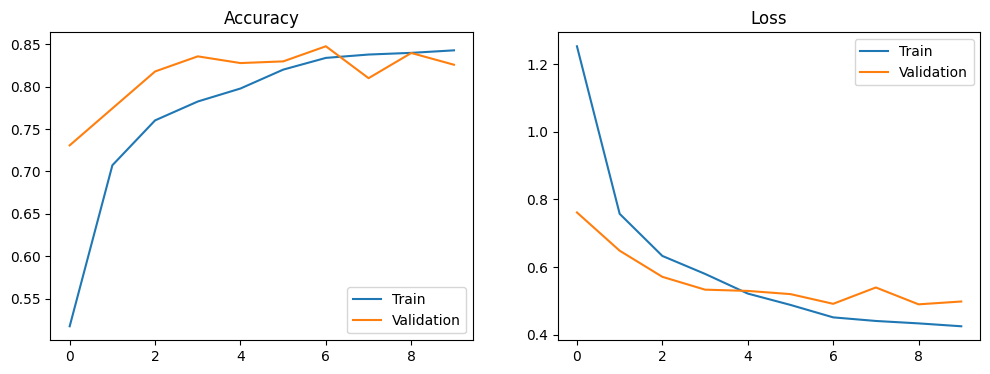

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()
plt.show()

In [ ]:
loss, acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {acc * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 16s 993ms/step - accuracy: 0.8297 - loss: 0.4988
Validation Accuracy: 82.97%


              precision    recall  f1-score   support

   cardboard       0.91      0.90      0.91        69
       glass       0.79      0.92      0.85       102
       metal       0.70      0.90      0.79        88
       paper       0.92      0.88      0.90       123
     plastic       0.91      0.66      0.77        89
       trash       0.74      0.50      0.60        34

    accuracy                           0.83       505
   macro avg       0.83      0.79      0.80       505
weighted avg       0.84      0.83      0.83       505



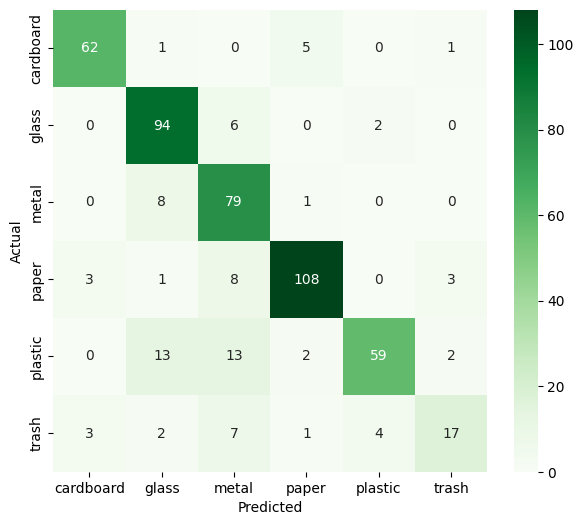

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(y_true, y_pred, target_names=class_names))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names,
            yticklabels=class_names, cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
model.save("waste_classifier.keras")

In [ ]:
def predict_image(path):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)
    pred = model.predict(arr, verbose=0)
    label = class_names[np.argmax(pred)]
    conf = np.max(pred) * 100
    plt.imshow(img)
    plt.title(f"{label} ({conf:.1f}%)")
    plt.axis("off")
    plt.show()

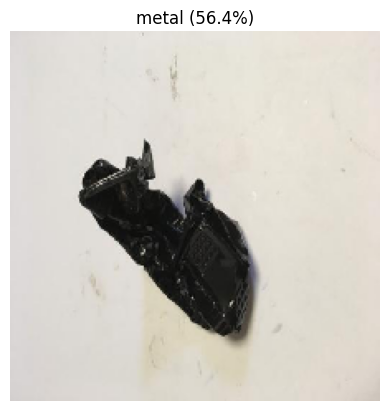

In [ ]:
import os
test_path = os.path.join(DATA_DIR, "plastic", os.listdir(os.path.join(DATA_DIR, "plastic"))[0])
predict_image(test_path)

Saving images (16).jpg to images (16).jpg
Testing: images (16).jpg


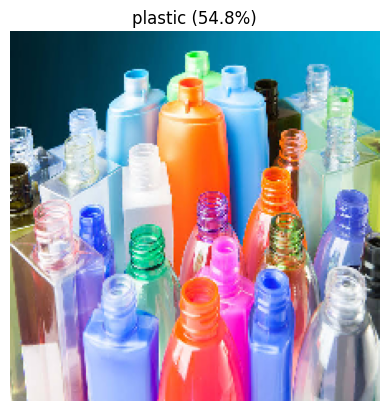

In [ ]:
from google.colab import files

uploaded = files.upload()   # "Choose Files" button aayega, apni image select karo

for filename in uploaded.keys():
    print("Testing:", filename)
    predict_image(filename)